# Salary Prediction

Corresponding  with this notebook is a slide deck where you will need to update all the portions in red.  Completing the notebook will provide all the results needed for the slides.  **Correctly completing the slides is a required part of the project.**


## Table of Contents
- [Introduction](#intro)
- [Part I - Descriptive Statistics](#descriptive)
- [Part II - Regression](#regression)
- [Part III - Interpret Results](#interpret)


<a id='intro'></a>
### Introduction

Linear Regression is very commonly performed by data analysts and data scientists.  For this project, you will be working to understand the results of a Linear Regression model associated with salaries.  Your goal is to work through this notebook to understand what variables are related to salary, and how exactly they are related.

As a final check, assure you meet all the criteria on the rubric.

<a id='descriptive'></a>
#### Part I - Descriptive Statistics

To get started, let's import our libraries.

In [1]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import statsmodels.api as sm

random.seed(0)

For each of the parts of question `1` notice links to [pandas documentation](https://pandas.pydata.org/) is provided to assist with answering the questions.  Though there are other ways you could solve the questions, the documentation is provided to assist you with one fast way to find the answer to each question.


`1.a)` Now, read in the `salary_data.csv` data. Store it in `df`. Read in the dataset and take a look at the top few rows here. **This question is completed for you**:

In [2]:
df = pd.read_csv('salary_data.csv')
df.head(15)

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0
5,29.0,Male,Bachelor's,Marketing Analyst,2.0,55000.0
6,42.0,Female,Master's,Product Manager,12.0,120000.0
7,31.0,Male,Bachelor's,Sales Manager,4.0,80000.0
8,26.0,Female,Bachelor's,Marketing Coordinator,1.0,45000.0
9,38.0,Male,PhD,Senior Scientist,10.0,110000.0


`b)` Use the below cell to find the number of rows in the dataset. [Helpful pandas link - `Dataframe.shape`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html#pandas.DataFrame.shape)

In [3]:
print(f"Number of rows: {df.shape[0]}")

Number of rows: 375


`c)` Do any of the rows have missing values? [Helpful Pandas Link One](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isnull.html) and [Helpful Pandas Link Two](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sum.html)  

If there are missing values, determine a method for dealing with them.

In [4]:
print("Rows with missing values:")
df.isnull().sum()

Rows with missing values:


Age                    2
Gender                 2
Education Level        2
Job Title              2
Years of Experience    2
Salary                 2
dtype: int64

In [5]:
rows_with_missing_values = df[df.isnull().any(axis=1)]
print(f"The {len(rows_with_missing_values)} rows with missing values:")
rows_with_missing_values

The 2 rows with missing values:


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
172,NaN,NaN,NaN,NaN,NaN,NaN
260,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
print(f"Dropping the {len(rows_with_missing_values)} rows with missing values")
df = df.dropna()


Dropping the 2 rows with missing values


`d)` How many employees are in each `Education Level`? Build a bar chart to show the count of employees in each level.

In [7]:
print("Number of employees in each Education Level:\n")
print(df['Education Level'].value_counts())

Number of employees in each Education Level:

Education Level
Bachelor's    224
Master's       98
PhD            51
Name: count, dtype: int64


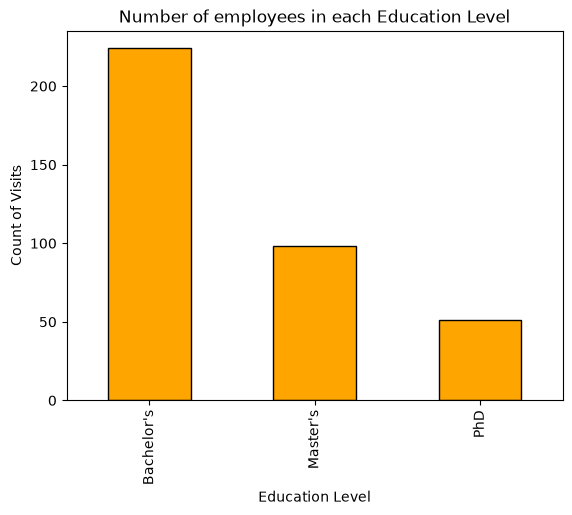

In [8]:
# bar chart of results - this part is done for you
df['Education Level'].value_counts().plot(kind='bar', color='orange', edgecolor='black');
plt.title('Number of employees in each Education Level');
plt.ylabel('Count of Visits');
plt.show();

`e)` What are the possible values for `Salary`?  What does the distribution of `Salary` look like?

In [9]:
print("Salary statistics:")
print(df['Salary'].describe())

print(f"\nPossible values for Salary are from {df['Salary'].min():.2f} to {df['Salary'].max():.2f}")


Salary statistics:
count       373.000000
mean     100577.345845
std       48240.013482
min         350.000000
25%       55000.000000
50%       95000.000000
75%      140000.000000
max      250000.000000
Name: Salary, dtype: float64

Possible values for Salary are from 350.00 to 250000.00


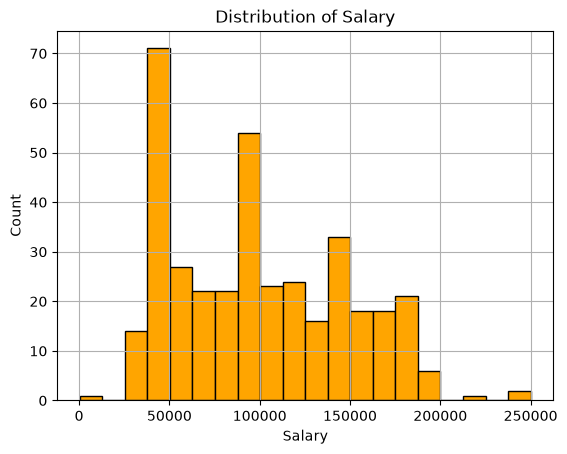

In [10]:
df['Salary'].hist(bins=20, color='orange', edgecolor='black')
plt.title('Distribution of Salary')
plt.ylabel('Count')
plt.xlabel('Salary')
plt.show()

<a id='regression'></a>
#### Part II - Regression

`1.` Now that you have had a chance to learn more about the dataset, let's look more at how different factors are related to `Salary`.

`a)` Consider average salary by gender, is there evidence that salaries are higher for one gender over the other?

In [11]:
# salary by gender
mean_salary_by_gender = df.groupby('Gender')['Salary'].mean().sort_values()

print("Salary by gender:\n")
print(mean_salary_by_gender)

group_that_earns_more = mean_salary_by_gender.index[-1] # -1 is last/highest
group_that_earns_less = mean_salary_by_gender.index[0] # 0 is first/lowest
salary_ratio = df.groupby('Gender')['Salary'].mean()[group_that_earns_more] / df.groupby('Gender')['Salary'].mean()[group_that_earns_less]

print(f"\nThe {group_that_earns_more} group earns {salary_ratio*100-100:.2f} % more than the {group_that_earns_less} group (on average).")

Salary by gender:

Gender
Female     97011.173184
Male      103867.783505
Name: Salary, dtype: float64

The Male group earns 7.07 % more than the Female group (on average).


`b)` Consider average salary by education level, is there evidence that salaries are higher for increased education?

In [12]:
print("Salary by education level:\n")
mean_salary_by_edu = df.groupby('Education Level')['Salary'].mean().sort_values()
print(mean_salary_by_edu)

# also have a group in the middle (vs. two above)
group_that_earns_less = mean_salary_by_edu.index[0] 
group_that_earns_intermediate = mean_salary_by_edu.index[1] # middle of ordered list
group_that_earns_more = mean_salary_by_edu.index[-1]

salary_ratio_top_to_bottom = mean_salary_by_edu[group_that_earns_more] / mean_salary_by_edu[group_that_earns_less]
salary_ratio_top_to_intermediate = mean_salary_by_edu[group_that_earns_more] / mean_salary_by_edu[group_that_earns_intermediate]
salary_ratio_intermediate_to_bottom = mean_salary_by_edu[group_that_earns_intermediate] / mean_salary_by_edu[group_that_earns_less]

print(f"\nThe {group_that_earns_more} group earns {salary_ratio_top_to_bottom*100-100:.2f} % more than the {group_that_earns_less} group (on average).")
print(f"The {group_that_earns_more} group earns {salary_ratio_top_to_intermediate*100-100:.2f} % more than the {group_that_earns_intermediate} group (on average).")
print(f"The {group_that_earns_intermediate} group earns {salary_ratio_intermediate_to_bottom*100-100:.2f} % more than the {group_that_earns_less} group (on average).")


Salary by education level:

Education Level
Bachelor's     74756.026786
Master's      129795.918367
PhD           157843.137255
Name: Salary, dtype: float64

The PhD group earns 111.14 % more than the Bachelor's group (on average).
The PhD group earns 21.61 % more than the Master's group (on average).
The Master's group earns 73.63 % more than the Bachelor's group (on average).


`c)` Consider average salary by years of experience, is there evidence that salaries are associated with increased years of experience?

In [13]:
print("Salary by years of experience:\n")
average_salary = df.groupby('Years of Experience')['Salary'].mean()
# average_salary.index = average_salary.index.astype(int)
average_salary


Salary by years of experience:



Years of Experience
0.0      33333.333333
0.5      35000.000000
1.0      37857.142857
1.5      36279.166667
2.0      41774.193548
3.0      51166.666667
4.0      58500.000000
5.0      64117.647059
6.0      83750.000000
7.0      84444.444444
8.0      88800.000000
9.0     101818.181818
10.0    100555.555556
11.0    100500.000000
12.0    105000.000000
13.0    120000.000000
14.0    125769.230769
15.0    134375.000000
16.0    157500.000000
17.0    143000.000000
18.0    149615.384615
19.0    166333.333333
20.0    168846.153846
21.0    173846.153846
22.0    162222.222222
23.0    177500.000000
24.0    250000.000000
25.0    200000.000000
Name: Salary, dtype: float64

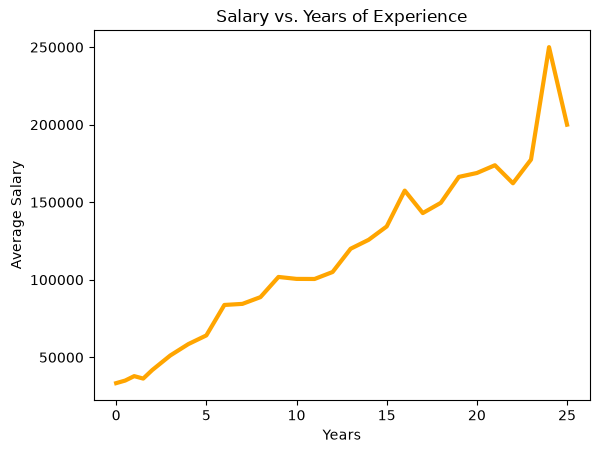

In [14]:
# this is best explored with something visual ...
plt.plot(average_salary.index, average_salary.values, color='orange', linewidth=3)
plt.title('Salary vs. Years of Experience')
plt.xlabel('Years')
plt.ylabel('Average Salary')
plt.show()

`d)`  To make use of Job Title column lets create bool flag based on word existiance


List of words:

* Director
* Junior
* Senior
* Manager
* Analyst
* Engineer

**This question is completed for you**

In [15]:
flag_words = ['director', 'junior', 'senior', 'manager', 'analyst', 'engineer']
df['Job Title'] = df['Job Title'].str.lower()

for word in flag_words:
    df['is_' + word] = df['Job Title'].str.contains(word).astype(int)

df = df.drop('Job Title', axis=1)
df.head(15)

,Age,Gender,Education Level,Years of Experience,Salary,is_director,is_junior,is_senior,is_manager,is_analyst,is_engineer
0,32.0,Male,Bachelor's,5.0,90000.0,0,0,0,0,0,1
1,28.0,Female,Master's,3.0,65000.0,0,0,0,0,1,0
2,45.0,Male,PhD,15.0,150000.0,0,0,1,1,0,0
3,36.0,Female,Bachelor's,7.0,60000.0,0,0,0,0,0,0
4,52.0,Male,Master's,20.0,200000.0,1,0,0,0,0,0
5,29.0,Male,Bachelor's,2.0,55000.0,0,0,0,0,1,0
6,42.0,Female,Master's,12.0,120000.0,0,0,0,1,0,0
7,31.0,Male,Bachelor's,4.0,80000.0,0,0,0,1,0,0
8,26.0,Female,Bachelor's,1.0,45000.0,0,0,0,0,0,0
9,38.0,Male,PhD,10.0,110000.0,0,0,1,0,0,0


`e)` Create a flag for gender where 1 is if a person is male and 0 if the person is not.

In [16]:
df = pd.get_dummies(df, columns=['Gender'], drop_first=True, dtype=int)
df = df.rename(columns={'Gender_Male': 'is_male'})  
df.head(15)

,Age,Education Level,Years of Experience,Salary,is_director,is_junior,is_senior,is_manager,is_analyst,is_engineer,is_male
0,32.0,Bachelor's,5.0,90000.0,0,0,0,0,0,1,1
1,28.0,Master's,3.0,65000.0,0,0,0,0,1,0,0
2,45.0,PhD,15.0,150000.0,0,0,1,1,0,0,1
3,36.0,Bachelor's,7.0,60000.0,0,0,0,0,0,0,0
4,52.0,Master's,20.0,200000.0,1,0,0,0,0,0,1
5,29.0,Bachelor's,2.0,55000.0,0,0,0,0,1,0,1
6,42.0,Master's,12.0,120000.0,0,0,0,1,0,0,0
7,31.0,Bachelor's,4.0,80000.0,0,0,0,1,0,0,1
8,26.0,Bachelor's,1.0,45000.0,0,0,0,0,0,0,0
9,38.0,PhD,10.0,110000.0,0,0,1,0,0,0,1


In [17]:
# convert the education level 
edu_dummies = pd.get_dummies(df['Education Level'], drop_first=True, dtype=int)
edu_dummies = edu_dummies.rename(columns={'Master\'s': 'has_master', 'PhD': 'has_phd'})
df = pd.concat([df, edu_dummies], axis=1)

# rename some columns so the naming is more consistent
df = df.rename(columns={
    'Years of Experience': 'years_of_experience', 
    'Age': 'age', 'Education Level': 
    'education_level',
    'Salary': 'salary'
})

df.head(15)

,age,education_level,years_of_experience,salary,is_director,is_junior,is_senior,is_manager,is_analyst,is_engineer,is_male,has_master,has_phd
0,32.0,Bachelor's,5.0,90000.0,0,0,0,0,0,1,1,0,0
1,28.0,Master's,3.0,65000.0,0,0,0,0,1,0,0,1,0
2,45.0,PhD,15.0,150000.0,0,0,1,1,0,0,1,0,1
3,36.0,Bachelor's,7.0,60000.0,0,0,0,0,0,0,0,0,0
4,52.0,Master's,20.0,200000.0,1,0,0,0,0,0,1,1,0
5,29.0,Bachelor's,2.0,55000.0,0,0,0,0,1,0,1,0,0
6,42.0,Master's,12.0,120000.0,0,0,0,1,0,0,0,1,0
7,31.0,Bachelor's,4.0,80000.0,0,0,0,1,0,0,1,0,0
8,26.0,Bachelor's,1.0,45000.0,0,0,0,0,0,0,0,0,0
9,38.0,PhD,10.0,110000.0,0,0,1,0,0,0,1,0,1


`f)` Use statsmodels to fit a linear model to predict salary using each of the features from `a-e`.  These include:
* Gender
* Job TItle
* Years of Experience
* Education

In [18]:
features = [
    'years_of_experience',
    'is_male',
    'is_director', 'is_junior', 'is_senior', 'is_manager', 'is_analyst', 'is_engineer',
    "has_master", "has_phd",
]

X = sm.add_constant(df[features].astype(float))
y = df['salary']

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 salary   R-squared:                       0.915
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     391.7
Date:                Sun, 25 Oct 2026   Prob (F-statistic):          2.41e-187
Time:                        22:31:31   Log-Likelihood:                -4090.6
No. Observations:                 373   AIC:                             8203.
Df Residuals:                     362   BIC:                             8246.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                3.212e+04   2

<a id='interpretation'></a>
### Part III - Interpret Results

`1.` Consider you are tasked with finding which features in your linear model are significantly related to salary.  Were there any features that were not significantly related to salary in your first model?  If not, remove those features and fit a new model.  Only keep the features that were significant from the original model.

In [19]:
# Answer and explanation for question 1:

# is_analyst and is_engineer are not significant, so we remove them. They both have a p-value well above 0.05 with 0.933 and 0.508. 
# We also drop is_junior with a p-value slightly above 0.05 with 0.068.

new_features = [
    'years_of_experience',
    'is_male',
    'is_director', 
    'is_senior', 
    'is_manager',
    'has_master', 
    'has_phd',
]

X2 = sm.add_constant(df[new_features].astype(float))
y2 = df['salary']

model2 = sm.OLS(y2, X2).fit()
print(model2.summary())


                            OLS Regression Results                            
Dep. Variable:                 salary   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     557.4
Date:                Sun, 25 Oct 2026   Prob (F-statistic):          1.46e-190
Time:                        22:31:31   Log-Likelihood:                -4092.6
No. Observations:                 373   AIC:                             8201.
Df Residuals:                     365   BIC:                             8233.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                2.876e+04   1

`a)` With each additional year of experience, what is the expected change in salary?  What is the 95% confidence interval of the change?

**Answer:**

With each year of experience the salary is on average **\$5,104.44** higher (with the other features fixed).

The 95% confidence interval of change is **\$4,755.93** to **\$5,452.95** (with the other features fixed).

`b)` What is the expected difference in salary between someone with a senior title and someone with none of the other title indications?

**Answer:**

Someone with a senior title is expected to earn on average **\$14,450** more than someone with none of the other title indications (with the other features fixed).

`c)` What is the expected difference in salary between someone with a PhD and an individual with no PhD nor master's degree?  What is the 95% confidence interval of the change?

**Answer:**

The difference between someone with PhD and no PhD nor Master's degree is on average **\$23,080** (with the other features fixed).

The 95% confidence interval of the change is **\$17,700 to $28,500**.

`d)` If a male employee has 5 years of experience as a senior engineer with a bachelor's degree, what is the expected salary of the employee?

**Answer:**

If a male employee has 5 years of experience as a senior engineer with a bachelor's degree the average salary is expected to be **\$76,361.84**.
```
$28,760.00 (intercept)
$25,522.19 (5 * years so 5 * 5104.4388)
 $7,629.65 (is_male)
$14,450.00 (is_senior)
------------
$76,361.84
```

Comment: `is_engineer` was dropped / is not significant

`e)` Imagine that the employee in question `d)` actually has a salary of $110,000, what would the residual be for this employee?

**Answer:**

The residual is **\$33,638.16**

\$110,000.00 - \$76,361.84 = \$33,638.16


`f)` How well do you think your model fits?  What metrics or plots would you consider to understand if this model does a good job of predicting salary?

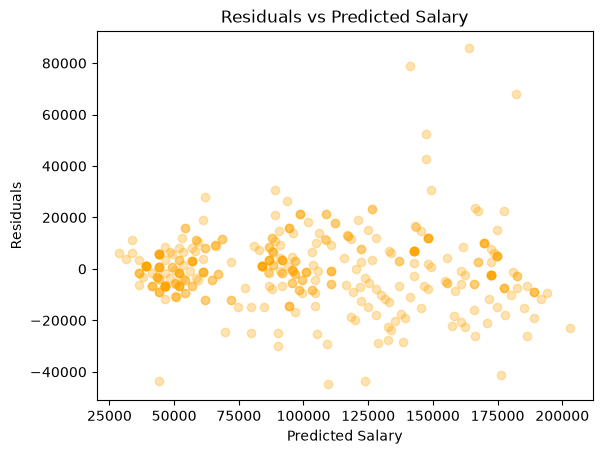

In [20]:
### Your work here

# plot the residuals vs. the predicted salary 
plt.scatter(model2.fittedvalues, model2.resid, alpha=0.3, color='orange')
plt.xlabel('Predicted Salary')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Salary')
plt.show()


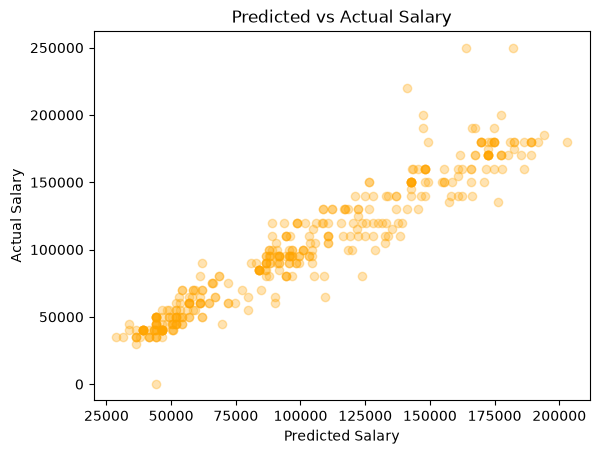

In [21]:
# plot predicted vs. actual salary
plt.scatter(model2.fittedvalues, df['salary'], alpha=0.3, color='orange')
plt.xlabel('Predicted Salary')
plt.ylabel('Actual Salary')
plt.title('Predicted vs Actual Salary')
plt.show()



In [22]:
print(model2.summary())


                            OLS Regression Results                            
Dep. Variable:                 salary   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     557.4
Date:                Sun, 25 Oct 2026   Prob (F-statistic):          1.46e-190
Time:                        22:31:31   Log-Likelihood:                -4092.6
No. Observations:                 373   AIC:                             8201.
Df Residuals:                     365   BIC:                             8233.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                2.876e+04   1

**Answer:**

The model fits well. R-squared = 0.914, so it explains about 91% of the variation in salary.

Looking at the residuals-vs-predicted plot, most residuals are scattered around 0 (roughly within +/- $20,000), which supports a decent linear fit. There are some larger outliers at higher predicted salaries, so it is not perfect.

In the predicted vs. actual plot, most points follow the diagonal (where predicted ~ actual) pretty closely, with more spread at higher salaries.
